# XStore Benchmarks – Big Data Congress 2024

## Initialize the environment 

In [1]:
import chi
from chi import lease, server, ssh, network
import os
import keystoneauth1, blazarclient
import uuid
import warnings
import time
from scripts.utilities import *
import scripts.session as session
warnings.filterwarnings('ignore')

CLOUD_SITE = "CHI@UC"
PROJECT_ID = "CHI-210854"
chi.set("project_name", PROJECT_ID)
chi.use_site(CLOUD_SITE)
uid_this = str(uuid.uuid4())

print(f"UID for this experiment is {uid_this}")

Now using CHI@UC:
URL: https://chi.uc.chameleoncloud.org
Location: Argonne National Laboratory, Lemont, Illinois, USA
Support contact: help@chameleoncloud.org
UID for this experiment is 4e1d766a-62e4-4895-bd18-18064281400f


## Configurations

In [2]:
numServer = 1
numClient = 8
instanceOS = "CC-Ubuntu22.04"
networkName = "XStore_Network"
subnetName = "XStore_Subnet"
routerName = "XStore_Router"

## Isolated network

In [3]:
# Pre-emptively nuke existing XStore network (if any)
try:
    network.nuke_network(networkName)
    time.sleep(10)
except RuntimeError:
    time.sleep(10)

isolatedNetwork = network.create_network(networkName, provider='physnet1')
isolatedNetwork_ID = isolatedNetwork['id']
subnet = chi.network.create_subnet(subnetName, isolatedNetwork_ID, cidr="192.168.1.0/24", gateway_ip=None)
router = chi.network.create_router(routerName, gw_network_name='public')
chi.network.add_subnet_to_router(router['id'], subnet['id'])

{'id': '386b0745-4629-4ba1-b177-db466e141c63',
 'tenant_id': '8d36e613c7d54f5bbbae886fb06d45e7',
 'port_id': '1398c752-1d72-43f3-a824-3e0f02f3ed63',
 'network_id': '45e3e526-21d9-46b2-a513-7fb9009411b3',
 'subnet_id': '35295977-844f-44f3-8d69-9f3fe556e0e4',
 'subnet_ids': ['35295977-844f-44f3-8d69-9f3fe556e0e4']}

## Make reservation
**Server**

In [4]:
serverReservation = []
try:
    print("Creating lease...")
    lease.add_fip_reservation(serverReservation, count=numServer)
    lease.add_node_reservation(serverReservation, count=numServer,
                               resource_properties=[">=", "$storage_devices.0.humanized_size", "960 GB"], architecture="x86_64")

    start_date, end_date = lease.lease_duration(days=1)

    l = lease.create_lease(
        f"XStore_Server_{uid_this}",
        serverReservation, 
        start_date=start_date,
        end_date=end_date)
    server_lease_id = l["id"]

    print("Waiting for lease to start ... This can take up to 1 min ...")
    lease.wait_for_active(server_lease_id)
    print("Lease is now active!")
except keystoneauth1.exceptions.http.Unauthorized as e:
    print("Unauthorized.\nDid set your project name and and run the code in the first cell?")
except blazarclient.exception.BlazarClientException as e:
    print(f"There is an issue making the reservation. Check the calendar to make sure a node is available.")
    print("https://chi.uc.chameleoncloud.org/project/leases/calendar/host/")
    print(e)
except Exception as e:
    print("An unexpected error happened.")
    print(e)

Creating lease...
Waiting for lease to start ... This can take up to 1 min ...
Lease is now active!


**Client**

In [5]:
clientReservation = []
try:
    print("Creating lease...")
    lease.add_fip_reservation(clientReservation, count=numClient)
    lease.add_node_reservation(clientReservation, count=numClient,
                               resource_properties=["=", "$node_type", "compute_cascadelake_r"], architecture="x86_64")

    start_date, end_date = lease.lease_duration(days=1)

    l = lease.create_lease(
        f"XStore_Client_{uid_this}",
        clientReservation, 
        start_date=start_date,
        end_date=end_date)
    client_lease_id = l["id"]

    print("Waiting for lease to start ... This can take up to 1 min ...")
    lease.wait_for_active(client_lease_id)
    print("Lease is now active!")
except keystoneauth1.exceptions.http.Unauthorized as e:
    print("Unauthorized.\nDid set your project name and and run the code in the first cell?")
except blazarclient.exception.BlazarClientException as e:
    print(f"There is an issue making the reservation. Check the calendar to make sure a node is available.")
    print("https://chi.uc.chameleoncloud.org/project/leases/calendar/host/")
    print(e)
except Exception as e:
    print("An unexpected error happened.")
    print(e)

Creating lease...
Waiting for lease to start ... This can take up to 1 min ...
Lease is now active!


## Launch server

We now launch the node on the bare metal servers we just reserved in the above cell. This could take up to 10-15 mins.

In [6]:
serverInstances = []
clientInstances = []

for i in range(numServer):
    s = server.create_server(f"XStore_Server-{i}_{uid_this}", image_name=instanceOS,
        reservation_id=lease.get_node_reservation(server_lease_id), network_id=isolatedNetwork_ID)
    serverInstances.append(s)
    
for i in range(numClient):
    s = server.create_server(f"XStore_Client-{i}_{uid_this}", image_name=instanceOS,
        reservation_id=lease.get_node_reservation(client_lease_id), network_id=isolatedNetwork_ID)
    clientInstances.append(s)    
    
for i in serverInstances:
    print(f"Waiting for {i.name} to start ...")
    server.wait_for_active(i.id)
    print(f"Instance: {i.name} has started\n")
    
for i in clientInstances:
    print(f"Waiting for {i.name} to start ...")
    server.wait_for_active(i.id)
    print(f"Instance: {i.name} has started\n")

Waiting for XStore_Server-0_4e1d766a-62e4-4895-bd18-18064281400f to start ...
Instance: XStore_Server-0_4e1d766a-62e4-4895-bd18-18064281400f has started

Waiting for XStore_Client-0_4e1d766a-62e4-4895-bd18-18064281400f to start ...
Instance: XStore_Client-0_4e1d766a-62e4-4895-bd18-18064281400f has started

Waiting for XStore_Client-1_4e1d766a-62e4-4895-bd18-18064281400f to start ...
Instance: XStore_Client-1_4e1d766a-62e4-4895-bd18-18064281400f has started

Waiting for XStore_Client-2_4e1d766a-62e4-4895-bd18-18064281400f to start ...
Instance: XStore_Client-2_4e1d766a-62e4-4895-bd18-18064281400f has started

Waiting for XStore_Client-3_4e1d766a-62e4-4895-bd18-18064281400f to start ...
Instance: XStore_Client-3_4e1d766a-62e4-4895-bd18-18064281400f has started

Waiting for XStore_Client-4_4e1d766a-62e4-4895-bd18-18064281400f to start ...
Instance: XStore_Client-4_4e1d766a-62e4-4895-bd18-18064281400f has started

Waiting for XStore_Client-5_4e1d766a-62e4-4895-bd18-18064281400f to start ..

Wait for the server's operating system to be ready for SSH connection.

In [7]:
server_ips = lease.get_reserved_floating_ips(server_lease_id)
client_ips = lease.get_reserved_floating_ips(client_lease_id)

for instance, ip in zip(serverInstances, server_ips):
    server.associate_floating_ip(instance.id, floating_ip_address=ip)

for instance, ip in zip(clientInstances, client_ips):
    server.associate_floating_ip(instance.id, floating_ip_address=ip)    
    
for instance, ip in zip(serverInstances, server_ips):
    print(f"Waiting for SSH connectivity on {ip} ...")
    server.wait_for_tcp(ip, 22)
    print(f"SSH to {ip} successful\n")
    
for instance, ip in zip(clientInstances, client_ips):
    print(f"Waiting for SSH connectivity on {ip} ...")
    server.wait_for_tcp(ip, 22)
    print(f"SSH to {ip} successful\n")
    
# Cache session
session.clear()
session.save({ "server_ips": server_ips, "server_lease_id": server_lease_id, "client_ips": client_ips, "client_lease_id": client_lease_id})

Waiting for SSH connectivity on 192.5.87.205 ...
SSH to 192.5.87.205 successful

Waiting for SSH connectivity on 192.5.87.209 ...
SSH to 192.5.87.209 successful

Waiting for SSH connectivity on 192.5.86.245 ...
SSH to 192.5.86.245 successful

Waiting for SSH connectivity on 192.5.86.206 ...
SSH to 192.5.86.206 successful

Waiting for SSH connectivity on 192.5.87.208 ...
SSH to 192.5.87.208 successful

Waiting for SSH connectivity on 192.5.87.204 ...
SSH to 192.5.87.204 successful

Waiting for SSH connectivity on 192.5.86.148 ...
SSH to 192.5.86.148 successful

Waiting for SSH connectivity on 192.5.86.208 ...
SSH to 192.5.86.208 successful

Waiting for SSH connectivity on 192.5.86.246 ...
SSH to 192.5.86.246 successful



## Initialize environment

In [8]:
# Update & Upgrade latest packages
for ip in (server_ips + client_ips):
    print(f"Processing: {ip}")
    conn = ssh.Remote(ip)
    conn.run("sudo apt update && sudo apt upgrade -y && sudo shutdown -r +1", hide=True)

Processing: 192.5.87.205
Processing: 192.5.87.209
Processing: 192.5.86.245
Processing: 192.5.86.206
Processing: 192.5.87.208
Processing: 192.5.87.204
Processing: 192.5.86.148
Processing: 192.5.86.208
Processing: 192.5.86.246


Wait for all server to come online after reboot

In [9]:
# 1' buffer of reboot
time.sleep(70)

for ip in (server_ips + client_ips):
    print(f"Waiting for SSH connectivity on {ip} ...")
    server.wait_for_tcp(ip, 22)
    print(f" - SSH to {ip} successful")

Waiting for SSH connectivity on 192.5.87.205 ...
 - SSH to 192.5.87.205 successful
Waiting for SSH connectivity on 192.5.87.209 ...
 - SSH to 192.5.87.209 successful
Waiting for SSH connectivity on 192.5.86.245 ...
 - SSH to 192.5.86.245 successful
Waiting for SSH connectivity on 192.5.86.206 ...
 - SSH to 192.5.86.206 successful
Waiting for SSH connectivity on 192.5.87.208 ...
 - SSH to 192.5.87.208 successful
Waiting for SSH connectivity on 192.5.87.204 ...
 - SSH to 192.5.87.204 successful
Waiting for SSH connectivity on 192.5.86.148 ...
 - SSH to 192.5.86.148 successful
Waiting for SSH connectivity on 192.5.86.208 ...
 - SSH to 192.5.86.208 successful
Waiting for SSH connectivity on 192.5.86.246 ...
 - SSH to 192.5.86.246 successful


## Datasets

Preparing test datasets on client nodes

In [10]:
for ip in client_ips:
    print(f"Processing: {ip}")
    conn = ssh.Remote(ip)
    conn.put("./scripts/initData.sh")
    conn.run("bash initData.sh", hide=True)

Processing: 192.5.87.209
Processing: 192.5.86.245
Processing: 192.5.86.206
Processing: 192.5.87.208
Processing: 192.5.87.204
Processing: 192.5.86.148
Processing: 192.5.86.208
Processing: 192.5.86.246


## Benchmark server (XStore)

Prepare benchmark server

In [11]:
for i in server_ips:
    print(f"Processing: {i}")
    conn = ssh.Remote(i)
    conn.put("./scripts/XStore/initXStoreServer.sh")
    conn.run("bash initXStoreServer.sh", hide=True)

Processing: 192.5.87.205


## Benchmark client (XStore)
Prepare benchmark client

In [12]:
for i in client_ips:
    print(f"Processing: {i}")
    conn = ssh.Remote(i)
    conn.put("./scripts/XStore/initXStoreClient.sh")
    conn.run("bash initXStoreClient.sh", hide=True)

Processing: 192.5.87.209
Processing: 192.5.86.245
Processing: 192.5.86.206
Processing: 192.5.87.208
Processing: 192.5.87.204
Processing: 192.5.86.148
Processing: 192.5.86.208
Processing: 192.5.86.246


## Experiments - Settings

In [13]:
targetThreads = [1, 2, 4, 8, 16, 32]
numClients = [i * len(client_ips) for i in targetThreads]

## Experiment – UNARY INSERT (SEQ)
**Perform experiments**

In [14]:
runInsert("UNARY_SEQ", targetThreads, server_ips[0], "XSTORE", client_ips, 0)

[Benchmark: 1] [Client: 192.5.87.209] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.245] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.206] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.204] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.148] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.246] - Downloaded 1 result files
[Benchmark: 2] [Client: 192.5.87.209] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.245] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.206] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.208] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.204] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.148] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.208] - Downloaded 2 result files
[Benchmark

**Visualization**

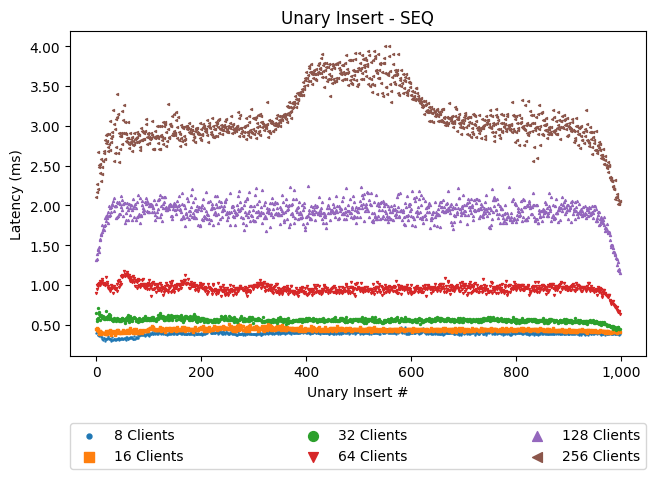

In [15]:
unaryPlots("INSERT_UNARY_SEQ", "XSTORE", targetThreads, client_ips)

## Experiment – UNARY INSERT (RAND)
**Perform experiments**

In [16]:
runInsert("UNARY_RAND", targetThreads, server_ips[0], "XSTORE", client_ips, 0)

[Benchmark: 1] [Client: 192.5.87.209] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.245] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.206] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.204] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.148] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.246] - Downloaded 1 result files
[Benchmark: 2] [Client: 192.5.87.209] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.245] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.206] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.208] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.204] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.148] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.208] - Downloaded 2 result files
[Benchmark

**Visualization**

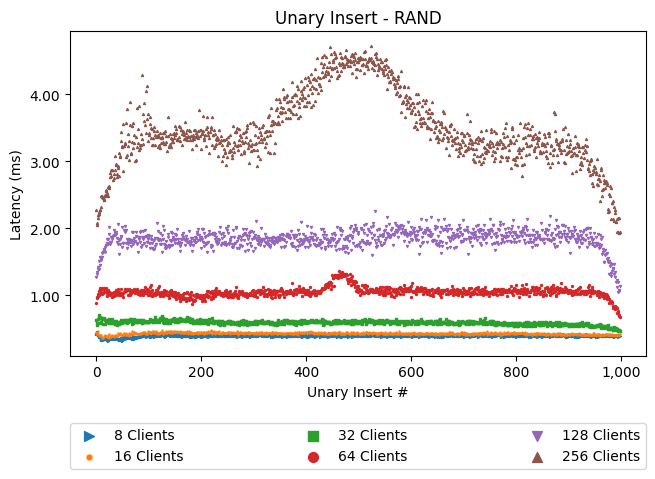

In [17]:
unaryPlots("INSERT_UNARY_RAND", "XSTORE", targetThreads, client_ips)

## Experiment – BATCH INSERT (SEQ)
**Perform experiments**

In [18]:
runInsert("BATCH_SEQ", targetThreads, server_ips[0], "XSTORE", client_ips, 10)

[Benchmark: 1] [Client: 192.5.87.209] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.245] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.206] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.204] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.148] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.246] - Downloaded 1 result files
[Benchmark: 2] [Client: 192.5.87.209] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.245] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.206] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.208] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.204] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.148] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.208] - Downloaded 2 result files
[Benchmark

**Visualization**

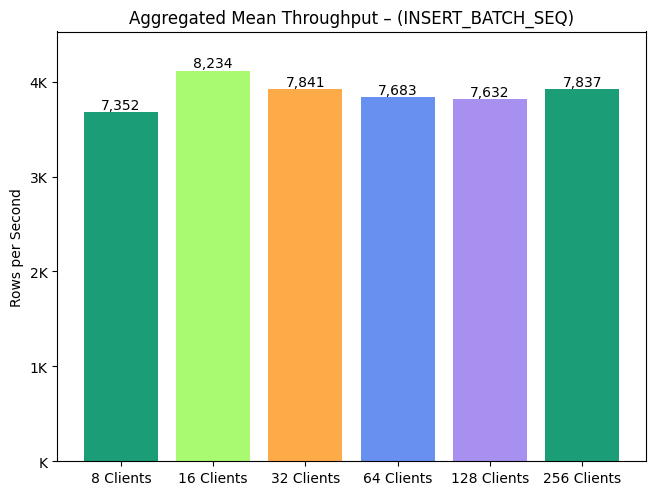

In [19]:
batchPlots("INSERT_BATCH_SEQ", "XSTORE", targetThreads, client_ips)

## Experiment – BATCH INSERT (RAND)
**Perform experiments**

In [20]:
runInsert("BATCH_RAND", targetThreads, server_ips[0], "XSTORE", client_ips, 10)

[Benchmark: 1] [Client: 192.5.87.209] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.245] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.206] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.204] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.148] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.246] - Downloaded 1 result files
[Benchmark: 2] [Client: 192.5.87.209] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.245] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.206] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.208] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.204] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.148] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.208] - Downloaded 2 result files
[Benchmark

**Visualization**

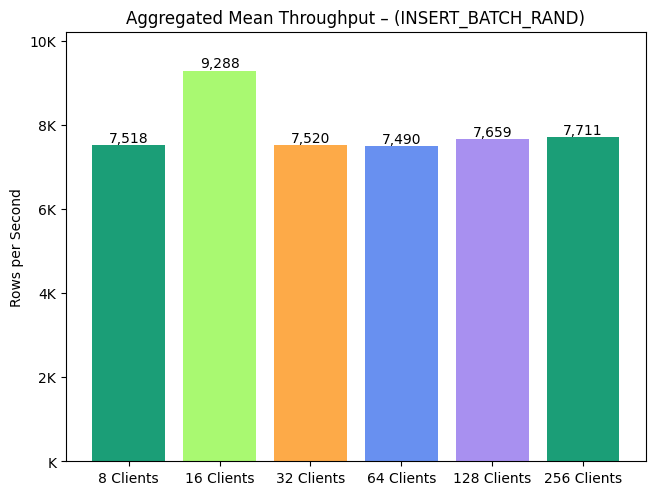

In [21]:
batchPlots("INSERT_BATCH_RAND", "XSTORE", targetThreads, client_ips)

## Bootstrap Database

<div class="alert alert-block alert-info">Note: This is required so that there's actual data for clients to query from</div>

In [22]:
for i in server_ips:
    print(f"Processing: {i}")
    conn = ssh.Remote(i)
    conn.put("./scripts/restoreDB.sh")
    conn.run("bash restoreDB.sh XStore")

Processing: 192.5.87.205
BENCH_DB/
BENCH_DB/2009.XSTORE
BENCH_DB/2008.XSTORE
BENCH_DB/2007.XSTORE
BENCH_DB/2006.XSTORE
BENCH_DB/2005.XSTORE
BENCH_DB/2004.XSTORE
BENCH_DB/2003.XSTORE
BENCH_DB/2002.XSTORE
BENCH_DB/2001.XSTORE
BENCH_DB/2000.XSTORE
BENCH_DB/BENCH_DB.CFG


## Experiment – UNARY QUERY (SEQ)

**Perform experiments**

In [23]:
runQuery("UNARY_SEQ", targetThreads, server_ips[0], "XSTORE", client_ips, 0)

[Benchmark: 1] [Client: 192.5.87.209] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.245] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.206] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.204] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.148] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.246] - Downloaded 1 result files
[Benchmark: 2] [Client: 192.5.87.209] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.245] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.206] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.208] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.204] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.148] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.208] - Downloaded 2 result files
[Benchmark

**Visualization**

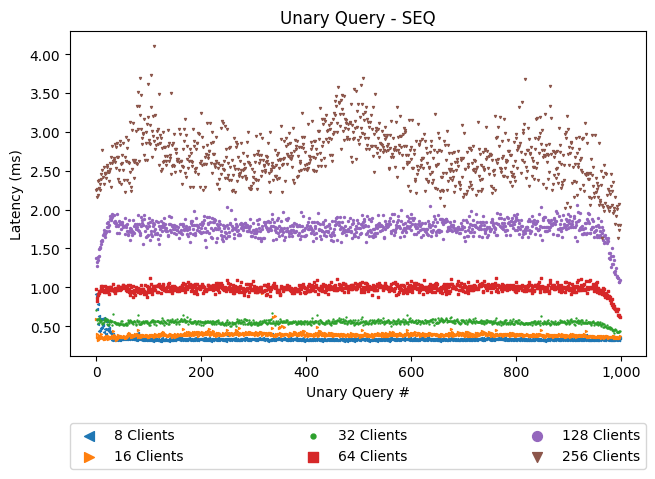

In [24]:
unaryPlots("QUERY_UNARY_SEQ", "XSTORE", targetThreads, client_ips)

## Experiment – UNARY QUERY (RAND)

**Perform experiments**

In [25]:
runQuery("UNARY_RAND", targetThreads, server_ips[0], "XSTORE", client_ips, 0)

[Benchmark: 1] [Client: 192.5.87.209] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.245] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.206] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.204] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.148] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.246] - Downloaded 1 result files
[Benchmark: 2] [Client: 192.5.87.209] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.245] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.206] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.208] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.204] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.148] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.208] - Downloaded 2 result files
[Benchmark

**Visualization**

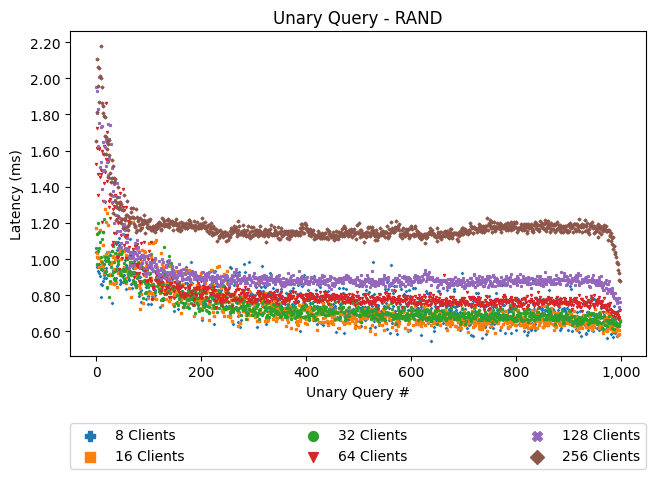

In [26]:
marker = itertools.cycle(("P" , "s" , "o" , "v" , "X" , "D", "*"))

def unaryPlots(WORKLOAD_TYPE, DB_NAME, targetThreads, clientNodes):
    numClients = [i * len(clientNodes) for i in targetThreads]
    
    benchData = {}
    for idx, i in enumerate(targetThreads):
        currCSVdata = []
        for node, ip in enumerate(clientNodes):
            myDir = f'{DB_NAME}_{WORKLOAD_TYPE}/Thread-{i}/Node-{node}'
            csvFiles = os.listdir(myDir)
            csvFiles = [csvFile for csvFile in csvFiles if csvFile.endswith(".csv")]

            for csvFile in csvFiles:
                df = pd.read_csv(f'{myDir}/{csvFile}')
                currCSVdata.append(df['Time taken (ms)'].tolist())
        df = pd.DataFrame(zip(*currCSVdata))
        df['Mean'] = df.mean(axis=1)
        benchData[f'Client-{numClients[idx]}'] = df['Mean'].tolist()[1:]

    df = pd.DataFrame(benchData)
    fig, ax = plt.subplots()

    for idx, i in enumerate(df.columns):
        currDF = df[i]
        plt.scatter(currDF.index, df[i], label=f'{numClients[idx]} Clients', s=2, marker=next(marker))

    # Labels & Legends
    ax.set_title(f'Unary {WORKLOAD_TYPE.split("_")[0].title()} - {WORKLOAD_TYPE.split("_")[-1]}')
    ax.set_xlabel(f'Unary {WORKLOAD_TYPE.split("_")[0].title()} #')
    ax.set_ylabel('Latency (ms)')
    # ax.set_yscale('log')
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.yaxis.set_minor_formatter(ticker.FormatStrFormatter("%.2f"))
    # ax.yaxis.set_minor_locator(ticker.NullLocator())  # no minor ticks
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    plt.legend(bbox_to_anchor=(0., -0.35, 1., 0.102), loc='lower center', mode='expand', ncols=3, borderaxespad=0., markerscale=5)
    plt.tight_layout(pad=0.15)
    plt.autoscale(axis='x')
    plt.savefig(f"{DB_NAME}_{WORKLOAD_TYPE}.svg", format='svg')
    
unaryPlots("QUERY_UNARY_RAND", "XSTORE", targetThreads, client_ips)

## Experiment – BATCH QUERY (SEQ)

**Perform experiments**

In [27]:
runQuery("BATCH_SEQ", targetThreads, server_ips[0], "XSTORE", client_ips, 10)

[Benchmark: 1] [Client: 192.5.87.209] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.245] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.206] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.204] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.148] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.246] - Downloaded 1 result files
[Benchmark: 2] [Client: 192.5.87.209] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.245] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.206] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.208] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.204] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.148] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.208] - Downloaded 2 result files
[Benchmark

**Visualization**

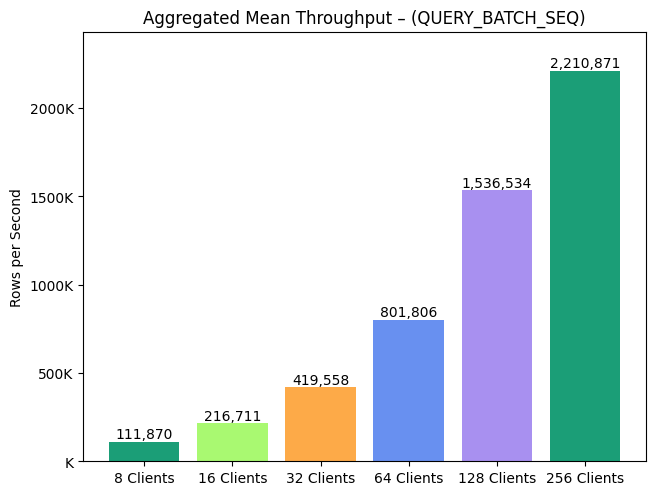

In [28]:
batchPlots("QUERY_BATCH_SEQ", "XSTORE", targetThreads, client_ips)

## Experiment – BATCH QUERY (RAND)

**Perform experiments**

In [29]:
runQuery("BATCH_RAND", targetThreads, server_ips[0], "XSTORE", client_ips, 10)

[Benchmark: 1] [Client: 192.5.87.209] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.245] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.206] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.87.204] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.148] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.208] - Downloaded 1 result files
[Benchmark: 1] [Client: 192.5.86.246] - Downloaded 1 result files
[Benchmark: 2] [Client: 192.5.87.209] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.245] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.206] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.208] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.87.204] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.148] - Downloaded 2 result files
[Benchmark: 2] [Client: 192.5.86.208] - Downloaded 2 result files
[Benchmark

**Visualization**

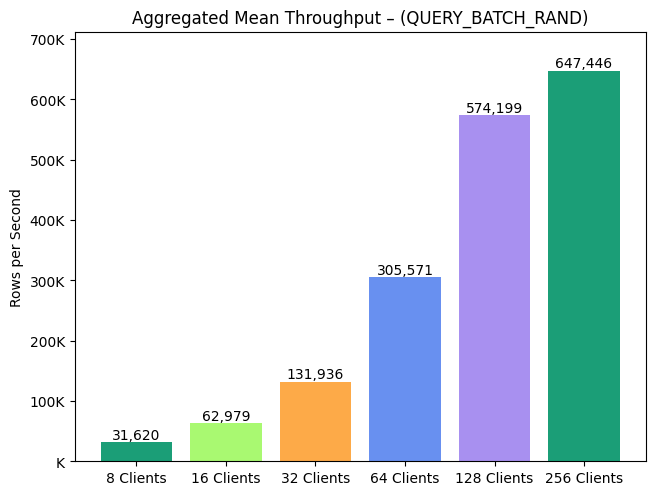

In [30]:
batchPlots("QUERY_BATCH_RAND", "XSTORE", targetThreads, client_ips)